The aim of this project is to apply the theoretical concepts we have learnt this past few months.  
We choose to apply Markowitz's portfolio theory for selecting optimal bond portfolios according to different metrics. We choose 5 ETFs to approximate the whole bond market differentiating by duration and geography:
- Invesco Euro Cash 3 Months UCITS ETF
- Invesco Euro Government Bond 3-5 Year UCITS ETF
- Vanguard Global Aggregate Bond UCITS ETF EUR Hedged
- Vanguard USD Emerging Markets Government Bond UCITS ETF
- iShares Global Government Bond UCITS ETF

Objective of the analysis: finding different portfolio that optimise different metrics. To work with the Equity Research division particularly important is the duration optimised portfolio.  
We then plot the efficient frontier to check our results and to have a global look.  
We finally verify Markowitz's theory limits we discussed this months by plotting efficient portfolios compositions.  

In [157]:
# Datafeed installation
!pip install tvDatafeed

Defaulting to user installation because normal site-packages is not writeable


ERROR: Could not find a version that satisfies the requirement tvDatafeed (from versions: none)

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\giang\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for tvDatafeed


In [158]:
# Importing libraries
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from tvDatafeed import TvDatafeed, Interval

**IMPORTING DATA AND DATASET CREATION**

In [159]:
# Accessing Trading View feed to import the data
tv = TvDatafeed()

In [160]:
# Importing data from Trading View
Money_Market = tv.get_hist(symbol='PEU',exchange='MIL',interval=Interval.in_daily, n_bars=5000) # Invesco Euro Cash 3 Months UCITS ETF
Short_term_bond = tv.get_hist(symbol='EIB5',exchange='MIL',interval=Interval.in_daily, n_bars=5000) # Invesco Euro Government Bond 3-5 Year UCITS ETF
Euro_bond_market = tv.get_hist(symbol='VAGF',exchange='MIL',interval=Interval.in_daily, n_bars=5000) # Vanguard Global Aggregate Bond UCITS ETF EUR Hedged
Emerging_markets_bonds = tv.get_hist(symbol='VDEA',exchange='MIL',interval=Interval.in_daily, n_bars=5000) # Vanguard USD Emerging Markets Government Bond UCITS ETF
Global_developed_bonds = tv.get_hist(symbol='IGLA',exchange='LSE',interval=Interval.in_daily, n_bars=5000) # iShares Global Government Bond UCITS ETF

In [161]:
# Selecting start and end dates
start_date = '2020-01-14'
end_date = '2023-10-14'

# Taking only the close and creating one combined dataset
data = pd.DataFrame({
    'Money_Market': Money_Market['close'],
    'Short_term_bond': Short_term_bond['close'],
    'Euro_bond_market': Euro_bond_market['close'],
    'Emerging_markets_bonds': Emerging_markets_bonds['close'],
    'Global_developed_bonds': Global_developed_bonds['close']
})

# Index in datetime format
data.index = pd.to_datetime(data.index)

data = data.loc[start_date:end_date]

# Dates sorted
data.sort_index(inplace=True)

# Sorting dates in descending order (just to be sure)
data_sorted = data.sort_index(ascending=False)

# Dropping NaN
data_cleaned = data_sorted.dropna()

# Check all columns have the same length
all_columns_same_length = data_cleaned.isnull().sum().sum() == 0
if all_columns_same_length:
    print("Dataset is clean and every column has the same length")
else:
    print("Dataset has missing values")


data_cleaned

Dataset is clean and every column has the same length


,Money_Market,Short_term_bond,Euro_bond_market,Emerging_markets_bonds,Global_developed_bonds
datetime,,,,,
2023-10-13 09:00:00,101.13,35.490002,21.620001,45.904999,4.2925
2023-10-12 09:00:00,101.07,35.459999,21.610001,45.615002,4.2895
2023-10-11 09:00:00,101.08,35.535000,21.665001,45.549999,4.3200
2023-10-10 09:00:00,101.07,35.525002,21.590000,45.580002,4.3025
2023-10-09 09:00:00,101.02,35.514999,21.549999,45.505001,4.2830
...,...,...,...,...,...
2020-01-20 09:00:00,100.83,39.540001,25.379999,49.735001,5.2930
2020-01-17 09:00:00,100.80,39.535000,25.379999,49.634998,5.3000
2020-01-16 09:00:00,100.85,39.560001,25.405001,49.485001,5.2960


**EXPECTED RETURNS, VARIANCE-COVARIANCE MATRIX, AND CORRELATION MATRIX**

In [162]:
# Computing returns
returns = data_cleaned.pct_change()[1:]

# Computing expected returns
expected_returns = returns.mean()*252  # annualised

# Computing variance-covariance matrix
covariance_matrix = returns.cov()
covariance_matrix = (covariance_matrix + covariance_matrix.T) / 2  # make it symmetric
covariance_matrix = covariance_matrix*252 # annualised

# Computing correlation matrix
correlation_matrix = returns.corr()

expected_returns

Money_Market             -0.000124
Short_term_bond           0.029681
Euro_bond_market          0.043860
Emerging_markets_bonds    0.025402
Global_developed_bonds    0.059230
dtype: float64

In [163]:
covariance_matrix

,Money_Market,Short_term_bond,Euro_bond_market,Emerging_markets_bonds,Global_developed_bonds
Money_Market,0.001298,-0.000036,0.000136,-0.000986,0.000089
Short_term_bond,-0.000036,0.001426,0.001314,0.001461,0.001921
Euro_bond_market,0.000136,0.001314,0.002822,0.001214,0.002976
Emerging_markets_bonds,-0.000986,0.001461,0.001214,0.011400,0.000939
Global_developed_bonds,0.000089,0.001921,0.002976,0.000939,0.006052


In [164]:
correlation_matrix

,Money_Market,Short_term_bond,Euro_bond_market,Emerging_markets_bonds,Global_developed_bonds
Money_Market,1.000000,-0.026481,0.071039,-0.256342,0.031773
Short_term_bond,-0.026481,1.000000,0.654808,0.362314,0.653789
Euro_bond_market,0.071039,0.654808,1.000000,0.214076,0.720163
Emerging_markets_bonds,-0.256342,0.362314,0.214076,1.000000,0.113099
Global_developed_bonds,0.031773,0.653789,0.720163,0.113099,1.000000


**OPTIMISATION FUNCTIONS**

In [165]:
# Function to compute portoflio expected return
def portfolio_return(weights, expected_returns):
    return np.dot(weights, expected_returns)

# Function to compute portfolio variance
def portfolio_variance(weights, covariance_matrix):
    return np.dot(weights.T, np.dot(covariance_matrix, weights))

# Function to compute portfolio risk (standard deviation)
def portfolio_risk(weights, covariance_matrix):
    return np.sqrt(portfolio_variance(weights, covariance_matrix))

# Function for weights sum constraint
def constraint_sum(weights):
    return np.sum(weights) - 1

# Function for duration target constraint
def constraint_duration(weights):
    return np.dot(weights, durations) - target_duration


**CONSTRAINTS**

In [166]:
categories = ['Money_Market', 'Short_term_bond', 'Euro_bond_market', 'Emerging_markets_bonds', 'Global_developed_bonds']
lb = [0, 0, 0, 0, 0]  # weights lower bound 
ub = [1, 1, 1, 1, 1]  # weights upper bound

Now a list of optimised portfolios considering different metrics.

**1. OPTIMISATION FOR TARGET DURATION**

In [167]:
target_duration = 2  # duration target in years
durations = np.array([0.17, 3.76, 6.5, 6, 7.17])  # asset durations

In [168]:
# Initializing weights to equally-weighted
num_assets = len(categories)
initial_weights = np.array([1.0 / num_assets] * num_assets)

In [169]:
# Constraint on duration
def constraint_duration(weights):
    return np.dot(weights, durations) - target_duration

# Objective function (minimising variance)
def objective_function_duration(weights, covariance_matrix):
    return portfolio_variance(weights, covariance_matrix)

# Other constraints
constraints_duration = [
    {'type': 'eq', 'fun': constraint_sum},  # weights sum = 1
    {'type': 'eq', 'fun': constraint_duration}  # duration target
]

# Bounds
bounds = [(lb[i], ub[i]) for i in range(len(categories))]

# Optimisation
result_duration = minimize(objective_function_duration, initial_weights, args=(covariance_matrix,), method='SLSQP', bounds=bounds, constraints=constraints_duration)

# Results
if result_duration.success:
    optimal_weights_duration = result_duration.x
    optimal_portfolio_return_duration = portfolio_return(optimal_weights_duration, expected_returns)
    optimal_portfolio_risk_duration = portfolio_risk(optimal_weights_duration, covariance_matrix)
    portfolio_duration_optimised = np.dot(optimal_weights_duration, durations)

    # Weights
    print("Optimal weights for target duration:")
    for i, category in enumerate(categories):
        print(f"{category}: {optimal_weights_duration[i]:.4f}")

    print(f"\nOptimal return for target duration: {optimal_portfolio_return_duration:.4%}")
    print(f"Optimal risk for target duration: {optimal_portfolio_risk_duration:.4%}")
    print(f"Optimal portfolio duration: {portfolio_duration_optimised:.2f} years")

else:
    print("\n Optimisation for target duration failed:", result_duration.message)

Optimal weights for target duration:
Money_Market: 0.5829
Short_term_bond: 0.2796
Euro_bond_market: 0.0489
Emerging_markets_bonds: 0.0886
Global_developed_bonds: 0.0000

Optimal return for target duration: 1.2623%
Optimal risk for target duration: 2.5726%
Optimal portfolio duration: 2.00 years


**2. OPTIMISATION FOR TARGET RETURN**

*Max possible return*

In [170]:
max_possible_return = expected_returns.max()
target_return = 0.05
print(f"Maximum possible return: {max_possible_return:.2%}")

if target_return > max_possible_return:
    raise ValueError(f"Error: A target_return of {target_return:.2%} is greater than the maximum possible return of {max_possible_return:.2%}. Reduce target_return.")

Maximum possible return: 5.92%


*Optimisation*

In [171]:
# Objective function (minimising variance)
def objective_function(weights, expected_returns, covariance_matrix):
    return portfolio_variance(weights, covariance_matrix)

# Constraint on return
def constraint_return(weights, expected_returns, target_return):
    return portfolio_return(weights, expected_returns) - target_return

# Constraints
constraints = ({'type': 'eq', 'fun': constraint_sum},   # Somma dei pesi = 1
               {'type': 'eq', 'fun': lambda w: constraint_return(w, expected_returns, target_return)})

# Bounds
bounds = [(lb[i], ub[i]) for i in range(len(categories))]

# Optimisation
result = minimize(objective_function, initial_weights, args=(expected_returns, covariance_matrix), method='SLSQP', bounds=bounds, constraints=constraints)

# Results
if result.success:
    optimal_weights = result.x
    optimal_portfolio_return = portfolio_return(optimal_weights, expected_returns)
    optimal_portfolio_risk = portfolio_risk(optimal_weights, covariance_matrix)
    portfolio_duration = np.dot(optimal_weights, durations)

    # Weights
    print("Optimal weights:")
    for i, category in enumerate(categories):
     print(f"{category}: {optimal_weights[i]:.4f}")

    print(f"\nOptimal return: {optimal_portfolio_return:.4%}")
    print(f"Optimal risk: {optimal_portfolio_risk:.4%}")
    print(f"Portfolio duration: {portfolio_duration:.2f} years")

else:
   print("Optimisation failed:", result.message)

Optimal weights:
Money_Market: 0.0000
Short_term_bond: 0.1049
Euro_bond_market: 0.3149
Emerging_markets_bonds: 0.0381
Global_developed_bonds: 0.5421

Optimal return: 5.0000%
Optimal risk: 5.9088%
Portfolio duration: 6.56 years


**3. OPTIMISATION FOR MINIMUM VARIANCE**

In [ ]:
# Objective function (minimising variance)
def objective_function_min_variance(weights, covariance_matrix):
    return portfolio_variance(weights, covariance_matrix)

# Constraints
constraints_min_variance = [{'type': 'eq', 'fun': constraint_sum}]  

# Bounds
bounds = [(lb[i], ub[i]) for i in range(len(categories))]

# Optimisation
result_min_variance = minimize(objective_function_min_variance, initial_weights, args=(covariance_matrix,),
                                method='SLSQP', bounds=bounds, constraints=constraints_min_variance, tol=1e-12)

# Results
if result_min_variance.success:
    optimal_weights_min_variance = result_min_variance.x
    optimal_portfolio_return_min_variance = portfolio_return(optimal_weights_min_variance, expected_returns)
    optimal_portfolio_risk_min_variance = portfolio_risk(optimal_weights_min_variance, covariance_matrix)
    portfolio_duration_min_variance = np.dot(optimal_weights_min_variance, durations)

    # Weights
    print("Optimal weights for minimum variance:")
    for i, category in enumerate(categories):
        print(f"{category}: {optimal_weights_min_variance[i]:.4f}")

    print(f"\nOptimal return for minimum variance: {optimal_portfolio_return_min_variance:.4%}")
    print(f"Optimal risk for minimum variance: {optimal_portfolio_risk_min_variance:.4%}")
    print(f"Portfolio duration: {portfolio_duration_min_variance:.2f} years")

else:
    print("\nOptimisation failed:", result_min_variance.message)


Optimal weights for minimum variance:
Money_Market: 0.5406
Short_term_bond: 0.4092
Euro_bond_market: 0.0000
Emerging_markets_bonds: 0.0502
Global_developed_bonds: 0.0000

Optimal return for minimum variance: 1.3354%
Optimal risk for minimum variance: 2.5249%
Portfolio duration: 1.93 years


**4. OPTIMISATION FOR MAXIMUM SHARPE RATIO**

In [173]:
# Importing the risk-free rate and computing its mean
risk_free_rates = tv.get_hist(symbol='US05Y',exchange='TVC',interval=Interval.in_daily, n_bars=5000)['close'].loc[start_date:end_date] / 100
rf_mean = np.mean(risk_free_rates)

# Computing the sharpe ratio
def sharpe_ratio(weights, expected_returns, covariance_matrix, rf_mean):
    port_return_minus_rf = np.dot(weights, (expected_returns - rf_mean))  # Expected portfolio return minus rf rate
    port_volatility = np.sqrt(np.dot(weights.T, np.dot(covariance_matrix, weights)))  # Portfolio volatility
    return - port_return_minus_rf / port_volatility  # Negative because we will minimise it

# Constraints
constraints_sharpe = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]  # Only the constraint on the weights sum

# Bounds
bounds = [(lb[i], ub[i]) for i in range(len(categories))]

# Optimisation
result_sharpe = minimize(sharpe_ratio, initial_weights, args=(expected_returns, covariance_matrix, rf_mean),
                         method='SLSQP', bounds=bounds, constraints=constraints_sharpe)

# Results
if result_sharpe.success:
    optimal_weights_sharpe = result_sharpe.x
    optimal_portfolio_return_sharpe = np.dot(optimal_weights_sharpe, expected_returns)
    optimal_portfolio_return_rf_sharpe = np.dot(optimal_weights_sharpe, (expected_returns-rf_mean))
    optimal_portfolio_risk_sharpe = np.sqrt(np.dot(optimal_weights_sharpe.T, np.dot(covariance_matrix, optimal_weights_sharpe)))
    portfolio_duration_sharpe = np.dot(optimal_weights_sharpe, durations)
    sharpe_opt =  optimal_portfolio_return_rf_sharpe / optimal_portfolio_risk_sharpe

    # Weights
    print("Optimal weights:")
    for i, category in enumerate(categories):
        print(f"{category}: {optimal_weights_sharpe[i]:.4f}")

    print(f"\nOptimal return: {optimal_portfolio_return_sharpe:.4%}")
    print(f"Optimal risk: {optimal_portfolio_risk_sharpe:.4%}")
    print(f"Portfolio duration: {portfolio_duration_sharpe:.2f} years")
    print(f"Optimal sharpe ratio: {sharpe_opt:.4f}")

else:
    print("\nOptimisation failed:", result_sharpe.message)

Optimal weights:
Money_Market: 0.0000
Short_term_bond: 0.0000
Euro_bond_market: 0.4135
Emerging_markets_bonds: 0.0000
Global_developed_bonds: 0.5865

Optimal return: 5.2874%
Optimal risk: 6.3308%
Portfolio duration: 6.89 years
Optimal sharpe ratio: 0.5204


**EFFICIENT FRONTIER**

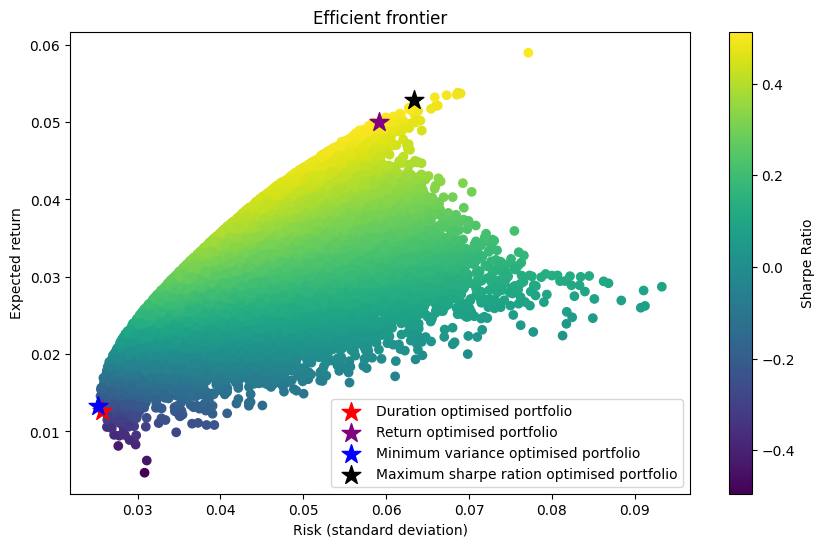

In [174]:
# Function to compute the efficient frontier
def efficient_frontier(expected_returns, covariance_matrix, lb, ub, rf_mean, num_portfolios=1000):
    results = np.zeros((3, num_portfolios))  # for returns, standard deviations and weights
    for i in range(num_portfolios):
        weights = np.array([np.random.uniform(lb[j], ub[j]) for j in range(num_assets)])  # random weights
        weights /= np.sum(weights)  # normalisation

        # Computing return and standard deviation
        portfolio_r = portfolio_return(weights, expected_returns)
        portfolio_volatility = portfolio_risk(weights, covariance_matrix)

        results[0,i] = portfolio_r  # return
        results[1,i] = portfolio_volatility  # risk
        results[2,i] = (portfolio_r - rf_mean) / portfolio_volatility  # sharpe ratio (optional)

    return results

# Efficient frontier
m = 100000
results = efficient_frontier(expected_returns, covariance_matrix, lb, ub, rf_mean, num_portfolios=m)

# Plotting efficient frontier
plt.figure(figsize=(10, 6))
plt.scatter(results[1,:], results[0,:], c=results[2,:], marker='o')
plt.xlabel('Risk (standard deviation)')
plt.ylabel('Expected return')
plt.title('Efficient frontier')
plt.colorbar(label='Sharpe Ratio')

# Adding previous optimised portfolios
plt.scatter(optimal_portfolio_risk_duration, optimal_portfolio_return_duration, color='red', marker='*', s=200, label='Duration optimised portfolio')
plt.scatter(optimal_portfolio_risk, optimal_portfolio_return, color='purple', marker='*', s=200, label='Return optimised portfolio')
plt.scatter(optimal_portfolio_risk_min_variance, optimal_portfolio_return_min_variance, color='blue', marker='*', s=200, label='Minimum variance optimised portfolio')
plt.scatter(optimal_portfolio_risk_sharpe, optimal_portfolio_return_sharpe,color='black', marker='*', s=200, label='Maximum sharpe ration optimised portfolio')

plt.legend()
plt.grid(False)
plt.show()

The minimum variance portfolio correctly stays on the far left of the chart, while the maximum sharpe ratio portfolio is on the yellow zone.

**PORTFOLIOS COMPOSITION ACROSS THE EFFICIENT FRONTIER**

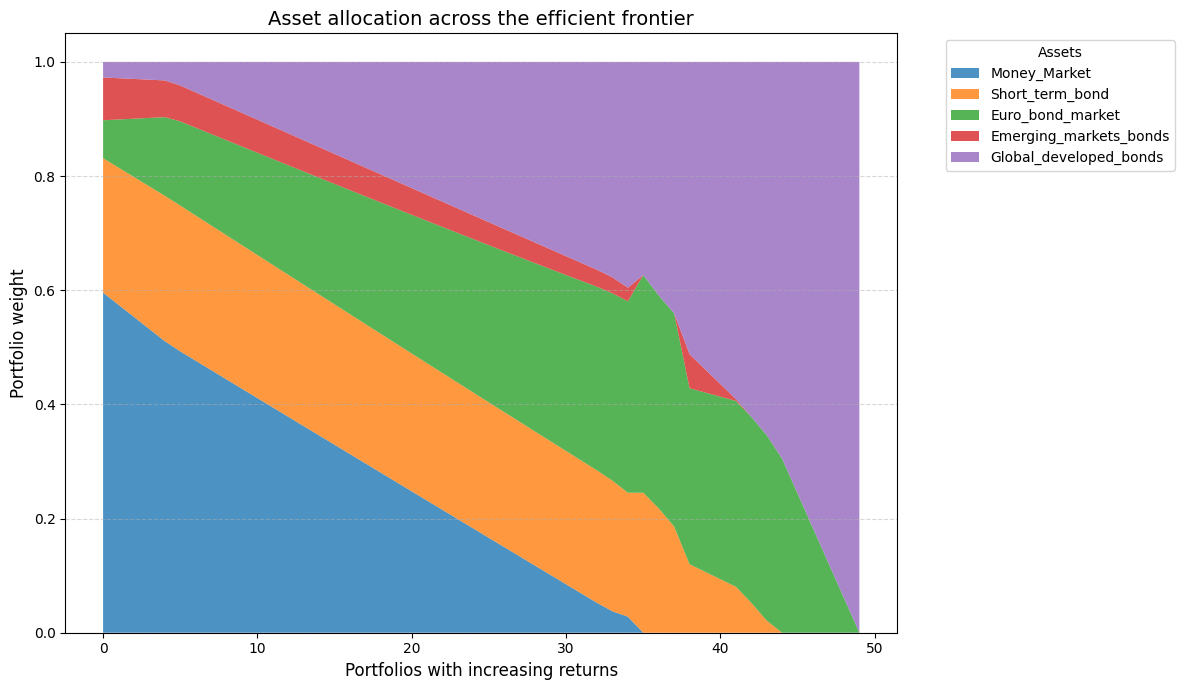

In [175]:
min_ret = optimal_portfolio_return_min_variance
max_ret = np.max(expected_returns)
num_points = 50  # Number of selected portfolios

target_returns = np.linspace(min_ret, max_ret, num_points)
efficient_weights = []

# Optimisation for every target return
for target in target_returns:
    # Constraints
    constraints = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}, # weights sum = 1
        {'type': 'eq', 'fun': lambda w: np.dot(w, expected_returns) - target} # target return
    ]
    
    # Optimisation (minimising variance)
    result = minimize(
        portfolio_variance, 
        initial_weights, 
        args=(covariance_matrix,), 
        method='SLSQP', 
        bounds=bounds, 
        constraints=constraints
    )
    
    # Saving optimal weights
    if result.success:
        efficient_weights.append(result.x)

# Converting ina numpy array
efficient_weights = np.array(efficient_weights)

# Plotting
plt.figure(figsize=(12, 7))
plt.stackplot(range(len(efficient_weights)), efficient_weights.T, labels=categories, alpha=0.8)

plt.title("Asset allocation across the efficient frontier", fontsize=14)
plt.xlabel("Portfolios with increasing returns", fontsize=12)
plt.ylabel("Portfolio weight", fontsize=12)
plt.legend(title="Assets", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

As expected when we want the highest possible return the Markowitz optimisation problem allocates the entire portfolio to the asset with the greatest past performance.  
On the other hand when we want to minimise risk the optimal portfolio is quite balanced (even though Money_Market accounts for nearly 60%)